EcoCore — Member 3: What-if Simulator / IBM LinuxONE (s390x)

This component does not train models or change workloads. It simulates three hypothetical options and recommends the eligible one with the smallest score.

1. Check where the Jupyter kernel is running

In [89]:
import platform, sys, os
print('Python:', sys.version.split()[0])
print('Architecture:', platform.machine())
print('LinuxONE/IBM Z compatible architecture:', platform.machine().lower() in ('s390x', 's390'))
print('Operating system:', platform.platform())
print('Container hint:', os.path.exists('/.dockerenv'))

Python: 3.12.15
Architecture: s390x
LinuxONE/IBM Z compatible architecture: True
Operating system: Linux-6.8.0-147-generic-s390x-with-glibc2.39
Container hint: True


2. Simulator engine

In [90]:
"""EcoCore Member 3: read-only what-if simulator for IBM Z / LinuxONE.

This module ONLY simulates hypothetical decisions. It never changes real
processes/workloads.

Member 2 integration contract:
    predictor.predict(metrics) -> {
        "risk_probability": float,
        "risk_level": "LOW"/"ELEVATED"/"HIGH",
        "important_signals": [...]
    }

The simulator converts that prediction into projected scenario risk scores.
"""
from __future__ import annotations

import math
from typing import Callable, Dict, List, Optional

# Adapter contract used internally by the simulator:
# predict_fn(projected_metrics, cpu_trend, memory_trend) -> float in [0, 1]
RiskPredictor = Callable[[dict, float, float], float]


def _bounded(value: float, lo: float, hi: float) -> float:
    return max(lo, min(hi, float(value)))


def _metric(metrics: dict, key: str, lower: float, upper: float) -> float:
    if key not in metrics:
        raise ValueError("Missing telemetry key: " + key)
    val = float(metrics[key])
    if not math.isfinite(val) or val < lower or val > upper:
        raise ValueError(f"{key} must be between {lower} and {upper}; got {val}")
    return val


def heuristic_pressure_score(metrics: dict, cpu_trend: float = 0.0,
                             memory_trend: float = 0.0) -> float:
    """Fallback score for testing when Member 2 model is unavailable."""
    cpu = float(metrics["cpu_pct"])
    mem = float(metrics["memory_pct"])
    load = float(metrics["load_per_core"])
    pressure_ratio = max(cpu / 80.0, mem / 85.0, load / 1.20)
    logit = (pressure_ratio - 0.94) * 8.0
    logit += max(cpu_trend, 0) * 0.025
    logit += max(memory_trend, 0) * 0.015
    logit = _bounded(logit, -30.0, 30.0)
    return float(1 / (1 + math.exp(-logit)))


def simulate_scenarios(
    metrics: dict,
    cpu_trend: float = 0.0,
    memory_trend: float = 0.0,
    predict_fn: Optional[RiskPredictor] = None,
    horizon_samples: int = 3,
    defer_cpu_relief: float = 15.0,
    defer_memory_relief: float = 5.0,
    redistribute_cpu_relief: float = 10.0,
    redistribute_memory_overhead: float = 2.0,
    allow_defer = True,
    target_capacity_available = False,
    target_compatible = False,
) -> List[Dict]:
    """Compare three hypothetical actions; no real workload is modified."""
    cpu = _metric(metrics, "cpu_pct", 0, 100)
    mem = _metric(metrics, "memory_pct", 0, 100)
    load = _metric(metrics, "load_per_core", 0, 10)

    for value, name in [
        (cpu_trend, "cpu_trend"), (memory_trend, "memory_trend"),
        (defer_cpu_relief, "defer_cpu_relief"),
        (defer_memory_relief, "defer_memory_relief"),
        (redistribute_cpu_relief, "redistribute_cpu_relief"),
        (redistribute_memory_overhead, "redistribute_memory_overhead"),
    ]:
        if not math.isfinite(float(value)):
            raise ValueError(f"{name} must be finite")

    if not isinstance(horizon_samples, int) or not 1 <= horizon_samples <= 12:
        raise ValueError("horizon_samples must be an integer from 1 to 12")

    predictor = predict_fn if predict_fn is not None else heuristic_pressure_score
    risk_kind = "member_2_model" if predict_fn else "heuristic_fallback"

    choices = [
        ("No action", 0.0, 0.0, 1.0, 0.00, True,
         "Current workload continues; no intervention."),
        ("Defer background workload", -float(defer_cpu_relief),
         -float(defer_memory_relief), 0.45, 0.04, bool(allow_defer),
         "Assumes only non-critical background work is deferred."),
        ("Redistribute workload", -float(redistribute_cpu_relief),
         float(redistribute_memory_overhead), 0.60, 0.06,
         bool(target_capacity_available and target_compatible),
         "Requires a compatible target with spare capacity."),
    ]

    results = []
    for name, dcpu, dmem, trend_scale, penalty, available, explanation in choices:
        projected_cpu = _bounded(
            cpu + cpu_trend * horizon_samples * trend_scale + dcpu, 0, 100
        )
        projected_mem = _bounded(
            mem + memory_trend * horizon_samples * trend_scale + dmem, 0, 100
        )
        projected_load = _bounded(
            load + cpu_trend * horizon_samples * trend_scale * 0.0037
            + dcpu * 0.007, 0, 3
        )

        projected_metrics = {
            **metrics,
            "cpu_pct": projected_cpu,
            "memory_pct": projected_mem,
            "load_per_core": projected_load,
            "cpu_trend": 0.0,
            "memory_trend": 0.0,
        }

        raw_risk = float(predictor(projected_metrics, 0.0, 0.0))
        if not math.isfinite(raw_risk) or not 0 <= raw_risk <= 1:
            raise ValueError("predict_fn must return a finite score between 0 and 1")

        if not available:
            if name == "Redistribute workload":
                restriction = "Unavailable: requires confirmed compatible destination and spare capacity."
            elif name == "Defer background workload":
                restriction = "Unavailable: no safe-to-defer background work."
            else:
                restriction = ""
        else:
            restriction = ""

        results.append({
            "action": name,
            "available": available,
            "estimated_risk": round(raw_risk, 6),
            "projected_cpu_pct": round(projected_cpu, 2),
            "projected_memory_pct": round(projected_mem, 2),
            "projected_load_per_core": round(projected_load, 3),
            "intervention_penalty": penalty,
            "decision_score": round(raw_risk + penalty, 6) if available else None,
            "risk_method": risk_kind,
            "assumptions": explanation,
            "restriction": restriction,
        })

    return results


def recommend(scenarios: List[Dict]) -> Dict:
    """Recommend the eligible scenario with the lowest decision score."""
    valid = [
        row for row in scenarios
        if row.get("available") and row.get("decision_score") is not None
    ]
    if not valid:
        raise ValueError("No available scenarios")
    return min(valid, key=lambda row: (row["decision_score"], row["intervention_penalty"]))


3. Edit these inputs

In [91]:
MODE = "demo"  # Change to "team_metrics" only when Member 1 telemetry variables exist.

demo_metrics = {
    "cpu_pct": 95.0,
    "memory_pct": 88.0,
    "load_per_core": 1.60,
    "process_count": 180,
    "logical_cores": 3,
}
demo_cpu_trend = 6.0
demo_memory_trend = 3.0

if MODE == "team_metrics":
    if "snapshot" not in globals() or "cpu_trend" not in globals() or "memory_trend" not in globals():
        raise RuntimeError("Run Member 1 telemetry cells first to define snapshot, cpu_trend, memory_trend.")
    input_metrics = dict(snapshot)
    ct, mt = float(cpu_trend), float(memory_trend)
else:
    input_metrics = demo_metrics.copy()
    ct, mt = demo_cpu_trend, demo_memory_trend

# Safe defaults: redistribution stays unavailable until a target is verified.
ALLOW_DEFER = True
TARGET_HAS_CAPACITY = False
TARGET_IS_COMPATIBLE = False

HORIZON_SAMPLES = 3
DEFER_CPU_RELIEF_PP = 15.0
DEFER_MEMORY_RELIEF_PP = 5.0
REDISTRIBUTE_CPU_RELIEF_PP = 10.0
REDISTRIBUTE_MEMORY_OVERHEAD_PP = 2.0

print("Metric source:", MODE, "| Values:", input_metrics)
print(f"CPU trend {ct:+.1f} pp/sample; memory trend {mt:+.1f} pp/sample")


Metric source: demo | Values: {'cpu_pct': 95.0, 'memory_pct': 88.0, 'load_per_core': 1.6, 'process_count': 180, 'logical_cores': 3}
CPU trend +6.0 pp/sample; memory trend +3.0 pp/sample


4. Connect Member 2 predictor when available

In [92]:
USE_MEMBER2_MODEL = True

if USE_MEMBER2_MODEL:
    try:
        from predictor import predict
    except ImportError as exc:
        raise RuntimeError(
            "predictor.py not found. Put Member 2's predictor.py in the same folder as this notebook."
        ) from exc

    def member2_predict_adapter(projected_metrics, cpu_trend=0.0, memory_trend=0.0):
        """Adapter: Member 3 simulator -> Member 2 predictor.py."""
        model_metrics = dict(projected_metrics)
        model_metrics["cpu_trend"] = float(cpu_trend)
        model_metrics["memory_trend"] = float(memory_trend)

        result = predict(model_metrics)

        if not isinstance(result, dict) or "risk_probability" not in result:
            raise ValueError("predictor.predict() must return a dict containing risk_probability")

        return float(result["risk_probability"])

    selected_predict_fn = member2_predict_adapter
    print("Scoring: Member 2 predictor.py")
else:
    selected_predict_fn = None
    print("Scoring: heuristic fallback (NOT the ML model)")


Scoring: Member 2 predictor.py


5. Run the three what-if choices

In [93]:
scenarios = simulate_scenarios(
    input_metrics, ct, mt,
    predict_fn=selected_predict_fn,
    horizon_samples=HORIZON_SAMPLES,
    defer_cpu_relief=DEFER_CPU_RELIEF_PP,
    defer_memory_relief=DEFER_MEMORY_RELIEF_PP,
    redistribute_cpu_relief=REDISTRIBUTE_CPU_RELIEF_PP,
    redistribute_memory_overhead=REDISTRIBUTE_MEMORY_OVERHEAD_PP,
    allow_defer=ALLOW_DEFER,
    target_capacity_available=TARGET_HAS_CAPACITY,
    target_compatible=TARGET_IS_COMPATIBLE,
)

best = recommend(scenarios)
for row in scenarios:
    state = 'AVAILABLE' if row['available'] else 'NOT AVAILABLE'
    score = 'n/a' if row['decision_score'] is None else f"{row['decision_score']:.3f}"
    print(f"{row['action']:<27} {state:<14} CPU={row['projected_cpu_pct']:5.1f}%"
          f"  RAM={row['projected_memory_pct']:5.1f}%  Pressure={row['estimated_risk']:.1%}  Score={score}")
    if row['restriction']:
        print('   ', row['restriction'])
print('\nRECOMMENDATION:', best['action'])
print('ASSUMPTION:', best['assumptions'])
print('Warning: NOTHING has been executed on the IBM system.')

No action                   AVAILABLE      CPU=100.0%  RAM= 97.0%  Pressure=100.0%  Score=1.000
Defer background workload   AVAILABLE      CPU= 88.1%  RAM= 87.0%  Pressure=100.0%  Score=1.040
Redistribute workload       NOT AVAILABLE  CPU= 95.8%  RAM= 95.4%  Pressure=97.0%  Score=n/a
    Unavailable: requires confirmed compatible destination and spare capacity.

RECOMMENDATION: No action
ASSUMPTION: Current workload continues; no intervention.


6. Graph/table and export results

Saved: /home/ibm-user/ecocore_member3_results.csv


,action,available,estimated_risk,projected_cpu_pct,projected_memory_pct,projected_load_per_core,intervention_penalty,decision_score,risk_method,assumptions,restriction
0,No action,True,1.00,100.0,97.00,1.667,0.00,1.00,member_2_model,Current workload continues; no intervention.,
1,Defer background workload,True,1.00,88.1,87.05,1.525,0.04,1.04,member_2_model,Assumes only non-critical background work is d...,
2,Redistribute workload,False,0.97,95.8,95.40,1.570,0.06,NaN,member_2_model,Requires a compatible target with spare capacity.,Unavailable: requires confirmed compatible des...


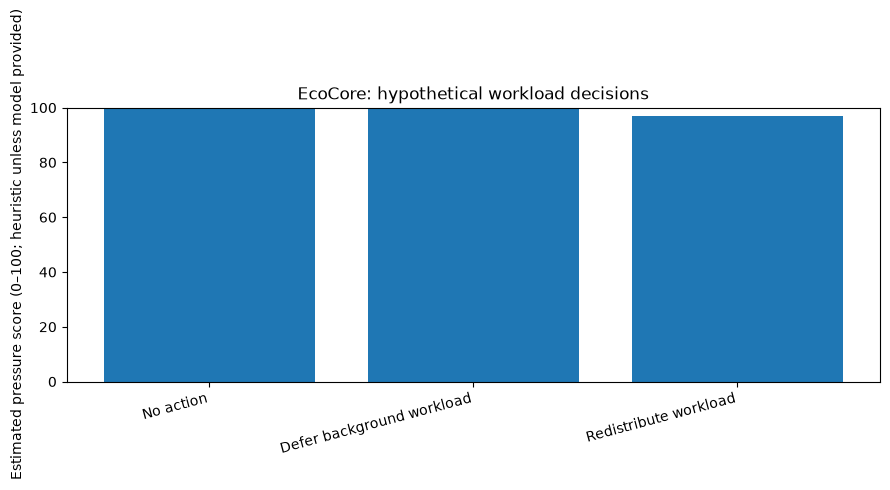

In [94]:
import csv
from pathlib import Path

output_file = Path('ecocore_member3_results.csv')
with output_file.open('w', newline='', encoding='utf-8') as file:
    writer = csv.DictWriter(file, fieldnames=list(scenarios[0].keys()))
    writer.writeheader()
    writer.writerows(scenarios)
print('Saved:', output_file.resolve())

try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(scenarios))
except ImportError:
    print('pandas not available; text results printed above.')

try:
    import matplotlib.pyplot as plt
    names = [s['action'] for s in scenarios]
    heights = [100 * s['estimated_risk'] for s in scenarios]
    plt.figure(figsize=(9, 4))
    plt.bar(names, heights)
    plt.ylabel('Estimated pressure score (0–100; heuristic unless model provided)')
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha='right')
    plt.title('EcoCore: hypothetical workload decisions')
    plt.tight_layout()
    plt.show()
except ImportError:
    print('matplotlib not available; CSV and printed table are sufficient.')

7. Quick verification tests

In [95]:
test_metrics = {'cpu_pct': 78.0, 'memory_pct': 73.0, 'load_per_core': 1.05, 'process_count': 130}
test_original = test_metrics.copy()
test_rows = simulate_scenarios(test_metrics, cpu_trend=4.0, memory_trend=1.5)
assert len(test_rows) == 3
assert test_metrics == test_original
assert not test_rows[2]['available']  # No verified destination by default
assert recommend(test_rows)['action'] != 'Redistribute workload'
assert all(0 <= r['projected_cpu_pct'] <= 100 for r in test_rows)
assert all(0 <= r['estimated_risk'] <= 1 for r in test_rows)
assert simulate_scenarios(test_metrics, allow_defer=False)[1]['available'] is False
assert simulate_scenarios(test_metrics, target_capacity_available=True, target_compatible=True)[2]['available'] is True
print('PASS: 7 notebook assertions; no IBM system changes made.')

PASS: 7 notebook assertions; no IBM system changes made.


In [96]:
# Optional standalone-module import test.
# If ecocore_simulator.py has been exported beside this notebook:
try:
    from ecocore_simulator import simulate_scenarios, recommend
    print("Standalone ecocore_simulator.py imported successfully!")
except ImportError:
    print("Notebook simulator functions are active; standalone .py export not present yet.")


Standalone ecocore_simulator.py imported successfully!


In [97]:
metrics = {
    "cpu_pct": 78.0,
    "memory_pct": 73.0,
    "load_per_core": 1.05,
    "process_count": 130
}

results = simulate_scenarios(
    metrics,
    cpu_trend=4.0,
    memory_trend=1.5,
    allow_defer=True,
    target_capacity_available=False,
    target_compatible=False
)

for result in results:
    print(
        result["action"],
        "| Available:", result["available"],
        "| Score:", result["decision_score"]
    )

best = recommend(results)

print("\nRecommended action:", best["action"])

No action | Available: True | Score: 0.814573
Defer background workload | Available: True | Score: 0.376261
Redistribute workload | Available: False | Score: None

Recommended action: Defer background workload


In [98]:
results = simulate_scenarios(
    metrics,
    cpu_trend=4.0,
    memory_trend=1.5,
    allow_defer=False,
    target_capacity_available=True,
    target_compatible=True
)

for result in results:
    print(
        result["action"],
        result["decision_score"],
        result["restriction"]
    )

print(
    "Recommendation:",
    recommend(results)["action"]
)

No action 0.814573 
Defer background workload None Unavailable: no safe-to-defer background work.
Redistribute workload 0.56 
Recommendation: Redistribute workload


In [99]:
def member2_predict_adapter(metrics, cpu_trend=0.0, memory_trend=0.0):
    """
    Adapter between Member 2's predict() output
    and Member 3's simulator.
    """

    metrics_for_model = dict(metrics)

    metrics_for_model["cpu_trend"] = cpu_trend
    metrics_for_model["memory_trend"] = memory_trend

    result = predict(metrics_for_model)

    return float(result["risk_probability"])

In [100]:
from predictor import predict

print("Member 2 predictor loaded successfully")

Member 2 predictor loaded successfully
